Total training compute(in GFLOPs) for models found on the pareto frontier(Scaling laws for robust comparison).

In [ ]:
import numpy as np
from matplotlib import pyplot as plt

C = np.array([7.05e+6, 1.69e+7, 3.5e+7, 7.05e+7, 1.24e+8, 1.69e+8])  # considering first 7 models
Cmin, Cmax = C.min(), C.max()

target_logs = np.linspace(np.log10(Cmin), np.log10(Cmax), 5)

plt.figure()
plt.xscale("log")
plt.scatter(np.log10(C), np.zeros_like(C), label="Actual models")
plt.scatter(target_logs, np.zeros_like(target_logs), marker="x", label="Target log points")

plt.yticks([])
plt.xlabel("log10(GFLOPs)")
plt.legend()
plt.title("Actual compute vs. 5 target log-spaced baseline points")

plt.show()

C = np.array([7.05e+6, 1.5e+7, 1.69e+7, 3.5e+7, 7.05e+7, 1.24e+8, 1.69e+8, 3.52e+8,
              6.23e+8])  # considering first 9 models, assuming we have 64m samples
Cmin, Cmax = C.min(), C.max()

target_logs = np.linspace(np.log10(Cmin), np.log10(Cmax), 5)
plt.figure()
plt.xscale("log")
plt.scatter(np.log10(C), np.zeros_like(C), label="Actual models")
plt.scatter(target_logs, np.zeros_like(target_logs), marker="x", label="Target log points")

plt.yticks([])
plt.xlabel("log10(GFLOPs)")
plt.legend()
plt.title("Actual compute vs. 5 target log-spaced baseline points")

plt.show()

Baseline results plotting

In [ ]:
from train.utils import plot_compute_vs_metric, Plotting

plot_compute_vs_metric("runs_config.csv", Plotting.VALIDATION_ERROR)
plot_compute_vs_metric("runs_config.csv", Plotting.TEST_ERROR)
plot_compute_vs_metric("runs_config.csv", Plotting.IMAGENET)
plot_compute_vs_metric("runs_config.csv", Plotting.MSCOCO_IMG)


Load CLIP model with custom vision and text tower

In [ ]:
from train.utils import precision_to_dtype
from train.clip_train.profiler import get_model_flops
from open_clip import create_model

model = create_model("local-dir:model_configs/ViT-B-32", precision="bf16")

get_model_flops(model, 100, dtype=precision_to_dtype("bf16"))


Batch size heuristic based on pareto frontier

In [ ]:
from train.utils import monotonic_bs, query_bs
import numpy as np

samples_seen = np.array([
    1280000.0,
    1280000.0,
    3072000.0,
    3072000.0,
    6400000.0,
    12800000.0,
    12800000.0,
    30720000.0,
    64000000.0,
    128000000.0,
    128000000.0,
    307200000.0,
    307200000.0,
    307200000.0,
    640000000.0,
    640000000.0,
    1280000000.0,
    640000000.0,
    3072000000.0,
    640000000.0
], dtype=float)

batch_size = np.array([
    512,
    512,
    512,
    512,
    2048,
    2048,
    2048,
    4096,
    4096,
    8192,
    8192,
    16384,
    16384,
    16384,
    32768,
    32768,
    65536,
    45056,
    90112,
    45056
], dtype=int)

ranges = monotonic_bs(samples_seen, batch_size)
print(ranges)
print(query_bs(705280005))


Infer hardware requirements

In [ ]:
import math

global_batch_size = 90624
local_bs = 128
max_gpus_per_node = 4

gpus_needed = global_batch_size // local_bs
gpus_per_node = min(gpus_needed, max_gpus_per_node)
nodes_nr = math.ceil(gpus_needed / max_gpus_per_node)

print(f"GPUs needed:{gpus_needed}")
print(f"GPUs per node:{gpus_per_node}")
print(f"Nodes number:{nodes_nr}")

In [ ]:
import neps

root_dir = "results/model=ViT-S-32/seed=0"
full_df, result = neps.status(root_dir)
print(full_df)


Max. amount of GFLOPs for our case

In [ ]:
from train.utils import precision_to_dtype
from train.clip_train.profiler import get_model_flops
from open_clip import create_model


def count_params(model):
    return sum(m.numel() for m in model.parameters())


nr_defined_samples = 130363082
model = create_model("local-dir:model_configs/ViT-S-32", precision="amp")

flops_amount = get_model_flops(model, nr_defined_samples, dtype=precision_to_dtype("amp"))
print(flops_amount)
print(count_params(model))


In [ ]:
from train.utils import build_model_cfg

build_model_cfg(text_width=256, vision_width=413,
                out_path="results/model=ViT-S-32/optimizer=experimental/seed=1/model_cfg/config_1")

GFLOPs to GPU hours mapping for RTX2080s and L40s

In [ ]:
from train.utils import add_gpu_hours_column, plot_measured_vs_predicted_gpu_hours
from train.flops_to_gpu_hours import GpuHoursModel
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

bs_rules = [
    {"min": 0.0, "max": 16915705.0, "bs": 512},
    {"min": 16915705.0, "max": 70528005.0, "bs": 1024},
    {"min": 70528005.0, "max": 169157005.0, "bs": 2048},
    {"min": 169157005.0, "max": 705280005.0, "bs": 4096},
    {"min": 705280005.0, "max": 1691570005.0, "bs": 8192},
]

new_bs_rules = [
    {"min": 0.0, "max": 1459000.0, "bs": 512},
    {"min": 1459000.0, "max": 7040000.0, "bs": 1024},
    {"min": 7040000.0, "max": 14590000.0, "bs": 2048},
    {"min": 14590000.0, "max": 70400000.0, "bs": 4096},
    {"min": 70400000.0, "max": 145900000.0, "bs": 8192},
]

PEAK_GFLOPS = {
    "RTX2080": 10300,
    "L40s": 90500,
    "NVIDIA A100-SXM4-40GB": 156000,
}

df = pd.concat(
    [
        pd.read_csv("runs_csvs/scale_space_only_search_seed_42.csv"),
        pd.read_csv("runs_csvs/scale_space_only_search_biased_sampling_seed_42.csv"),
    ],
    ignore_index=True,
)

A100_df = pd.concat(
    [
        pd.read_csv("runs_csvs/scale_space_only_search_biased_scale_juwels_seed_40.csv"),
        pd.read_csv("runs_csvs/scale_space_only_search_juwels_seed_40.csv"),
        pd.read_csv("runs_csvs/scan_space_juwels_biased_scale_alpha_0_5_seed_40.csv"),
    ],
    ignore_index=True,
)

df = add_gpu_hours_column(df)
A100_df = add_gpu_hours_column(A100_df)

x_query = np.logspace(7, 9, 6)

for gpu_name in ["RTX2080", "L40s"]:
    model = GpuHoursModel.fit_from_df(
        df,
        gpu_name,
        bs_rules=bs_rules,
    )

    plot_measured_vs_predicted_gpu_hours(
        df,
        gpu_name=gpu_name,
        model=model,
        x_query=x_query,
    )

A100_gpu_name = "NVIDIA A100-SXM4-40GB"
A100_model = GpuHoursModel.fit_from_df(
    A100_df,
    A100_gpu_name,
    bs_rules=new_bs_rules,
    use_compute_col=False
)

plot_measured_vs_predicted_gpu_hours(
    A100_df,
    gpu_name=A100_gpu_name,
    model=A100_model,
    x_query=x_query,
)

plt.show()

GFLOPs distribution for different sampling strategies

In [ ]:
from train.flops_to_gpu_hours import SamplingStrategyPlotter
import pandas as pd
import numpy as np
import json


def gpu_hours_model():
    A100_gpu_name = "NVIDIA A100-SXM4-40GB"
    A100_df = pd.concat(
        [
            pd.read_csv("runs_csvs/scale_space_only_search_biased_scale_juwels_seed_40.csv"),
            pd.read_csv("runs_csvs/scale_space_only_search_juwels_seed_40.csv"),
            pd.read_csv("runs_csvs/scan_space_juwels_biased_scale_alpha_0_5_seed_40.csv"),
        ],
        ignore_index=True,
    )

    A100_model = GpuHoursModel.fit_from_df(
        A100_df,
        A100_gpu_name,
        bs_rules=new_bs_rules,
        use_compute_col=False
    )

    return A100_model


# uniform sampling in individual parameters does not imply uniform sampling in compute space!


dfs = {
    "random sampling": pd.read_csv("sampling_strategy_feat_distributions/random_sampling.csv"),
    "biased_sampling, alpha 1": pd.read_csv("sampling_strategy_feat_distributions/biased_sampling_alpha_1.csv"),
    "biased sampling, alpha 0.5": pd.read_csv("sampling_strategy_feat_distributions/biased_sampling_alpha_0_5.csv")
}

plotter = SamplingStrategyPlotter(dfs)

plotter.plot_default_suite(
    compute_col="total_compute",
    vision_col="vision_width",
    text_col="text_width",
    train_samples_col="train_num_samples",
    bins_compute=25,
    bins_train=25,
    title="Feature distributions per sampling strategy",
    density=False,
)

gflops_mean_per_strategy = {}
model = gpu_hours_model()

target_Ns = [100, 500, 1000]

with open("models_sizes.json", "r") as f:
    ckpt_sizes = json.load(f)

for name, df in dfs.items():
    gflops = pd.to_numeric(df["total_compute"], errors="coerce").to_numpy(dtype=float)
    gflops = gflops[np.isfinite(gflops) & (gflops > 0)]

    if gflops.size == 0:
        print(f"\n{name}\nNo valid total_compute values.")
        continue

    mean_gflops = float(np.mean(gflops))

    mean_gpu_hours_per_cfg = float(
        model.mapping_gflops_to_gpu_hours(np.array([mean_gflops]), mode="global_linear", as_dict=False).sum()
    )

    vision_width = pd.to_numeric(df["vision_width"], errors="coerce")
    text_width = pd.to_numeric(df["text_width"], errors="coerce")

    df["model_key"] = "v" + df["vision_width"].astype(int).astype(str) + "_t" + df["text_width"].astype(int).astype(str)
    df["model_size_gb"] = df["model_key"].map(ckpt_sizes)

    print(f"\n{name}")
    print(f"Mean GFLOPs per config: {mean_gflops:.4f}")
    print(f"Mean GPU hours per config: {mean_gpu_hours_per_cfg:.6f}")
    total_gb = df["model_size_gb"].sum()
    print(f"{name} total model size: {total_gb:.2f} GB")

    for N in target_Ns:
        total_gpu_hours = N * mean_gpu_hours_per_cfg
        print(f"Estimated GPU hours for N={N}: {total_gpu_hours:.4f}")

GPU_hours_left = 28000


def decade_percentages(train_samples: pd.Series, low: float = 0.6e6, high: float = 60e6):
    s = pd.to_numeric(train_samples, errors="coerce")
    s = s[np.isfinite(s)]
    s = s[(s >= low) & (s <= high)]
    total = int(s.shape[0])
    if total == 0:
        return (np.nan, np.nan, 0, 0, 0)

    split = low * 10
    first = int((s < split).sum())
    second = int((s >= split).sum())

    first_pct = 100.0 * first / total
    second_pct = 100.0 * second / total
    return first_pct, second_pct, first, second, total


first_pct, second_pct, first_cnt, second_cnt, total_cnt = decade_percentages(df["train_num_samples"])
print(f"Train_num_samples decade split (valid in [0.6M, 60M]): n={total_cnt}")
print(f"  0.6M–6M:  {first_cnt} configs ({first_pct:.2f}%)")
print(f"  6M–60M:   {second_cnt} configs ({second_pct:.2f}%)")

A single epoch size per each model config

In [ ]:
from train.utils import build_model_cfg
import subprocess
from pathlib import Path
import json

WIDTHS = [32, 64, 128, 192, 256, 320, 384, 448, 512]
CONFIG_ROOT = Path("generated_model_configs")

TRAIN_BASE_CMD = [
    "python", "-m", "clip_train.main"
]


def run_config(vw, tw):
    name = f"v{vw}_t{tw}"
    cfg_dir = CONFIG_ROOT / name

    vision_head_width = 32 if vw == 32 else 64
    text_heads = 1 if tw == 32 else tw // 64

    build_model_cfg(
        text_width=tw,
        vision_width=vw,
        out_path=cfg_dir,
        vision_head_width=vision_head_width,
        text_heads=text_heads,
    )

    cmd = TRAIN_BASE_CMD + [
        "--warmup-fraction", "0.5",
        "--batch-size", "4",
        "--precision", "amp",
        "--dataset-type", "webdataset",
        "--workers", "0",
        "--val-data", "validation_data/{00000000..00000004}.tar",
        "--epochs", "1",
        "--train-num-samples", "32",
        "--train-data", "validation_data/{00000000..00000004}.tar",
        "--lr-scheduler", "const",
        "--model", f"local-dir:{cfg_dir.as_posix()}",
        "--name", name
    ]

    print("\n==============================")
    print("Running", name)
    print("==============================")

    subprocess.run(cmd, check=True)


for vw in WIDTHS:
    for tw in WIDTHS:
        run_config(vw, tw)

ROOT = Path("logs")
OUTFILE = "ckpt_sizes.json"

sizes = {}

for model_dir in sorted(ROOT.iterdir()):
    if not model_dir.is_dir():
        continue

    name = model_dir.name
    ckpt = model_dir / "checkpoints" / "epoch_1.pt"

    if not ckpt.exists():
        print(f"Missing checkpoint: {name}")
        continue

    size_gb = ckpt.stat().st_size / (1024 ** 3)
    sizes[name] = round(size_gb, 4)

    print(f"{name}: {size_gb:.4f} GB")

with open(OUTFILE, "w") as f:
    json.dump(sizes, f, indent=2)

print("\nSaved to", OUTFILE)


In [ ]:
# Different possibilities
# 1. Inverse transform sampling(To map uniform random values to any target distribution, you use the inverse CDF of that distribution) of values from uniform distribution to exponential(lambda) distribution. We need to truncate and shift the distribution.
# 2. sample directly from a log distribution. Same logic by finding the inverse CDF.


import numpy as np
import matplotlib.pyplot as plt

lower = 0.6
upper = 60.0

x = np.linspace(lower, upper, 2000)

pdf_linear = np.ones_like(x) / (upper - lower)
pdf_log = 1.0 / (x * np.log(upper / lower))

plt.figure(figsize=(8, 5))
plt.plot(x, pdf_linear, label="Linear sampling", linewidth=2)
plt.plot(x, pdf_log, label="Log sampling (∝ 1/x)", linewidth=2)

plt.xlabel("train_num_samples (millions)")
plt.ylabel("Probability density")
plt.title("Probability density: linear vs log sampling")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


Warped log-uniform distribution

In [ ]:
# Different possibilities:
# 1. Inverse transform sampling(To map uniform random values to any target distribution, you use the inverse CDF of that distribution) of values from uniform distribution to exponential(lambda) distribution. We need to truncate and shift the distribution.
# 2. sample directly from a log distribution. Same logic by finding the inverse CDF. Could have another warping param.

import numpy as np
import matplotlib.pyplot as plt

lower = 0.6
upper = 60.0
n = 20000

# alpha = 1.0 pure log-uniform
# alpha > 1.0 increasingly biased towards the lower bound
alpha = 1.0

rng = np.random.default_rng(42)
u = rng.uniform(0.0, 1.0, size=n)

samples = lower * (upper / lower) ** (u ** alpha)

plt.figure()
plt.scatter(np.arange(1, n + 1), samples)
plt.xlabel("Sample index")
plt.ylabel("train_num_samples (millions)")
plt.title(f"Samples biased toward small values (alpha={alpha})")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure()
plt.hist(samples, bins=20)
plt.xlabel("train_num_samples (millions)")
plt.ylabel("Count")
plt.title(f"Histogram of 100 biased samples (alpha={alpha})")
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("results/optimizer=scan_space_final_biased_space_alpha_0_5/configs_summary.csv")

vision = df["vision_width"]
text = df["text_width"]

total_samples = df["train_num_samples"] * df["epochs"]
vision_counts = vision.value_counts().sort_index()

plt.figure()
plt.bar(vision_counts.index.astype(str), vision_counts.values)
plt.xlabel("vision_width")
plt.ylabel("count")
plt.title("Distribution of vision_width")
plt.show()

text_counts = text.value_counts().sort_index()

plt.figure()
plt.bar(text_counts.index.astype(str), text_counts.values)
plt.xlabel("text_width")
plt.ylabel("count")
plt.title("Distribution of text_width")
plt.show()

plt.figure()
plt.hist(total_samples, bins=30)
# plt.xscale("log")
plt.xlabel("total_samples (train_num_samples × epochs, log scale)")
plt.ylabel("count")
plt.title("Distribution of total training samples")
plt.show()

lower_bound = 0.6e6
mid_point = 6e6
upper_bound = 60e6

total = len(total_samples)

first_decade = ((total_samples >= lower_bound) & (total_samples < mid_point)).sum()
second_decade = ((total_samples >= mid_point) & (total_samples <= upper_bound)).sum()

print("First decade count:", first_decade)
print("Second decade count:", second_decade)

print("First decade %:", 100 * first_decade / total)
print("Second decade %:", 100 * second_decade / total)

In [ ]:
import pandas as pd

df = pd.read_csv("results/scale_space_only_search_juwels/seed=40/configs_summary.csv")

df["train_num_samples"] = (
        pd.to_numeric(df["train_num_samples"], errors="coerce") * 1_000_000
).round().astype("Int64")

df.to_csv("results/scale_space_only_search_juwels/seed=40/configs_summary.csv", index=False)

C:\Users\Donat\Documents\Master\Thesis\vlm scaling laws repository\train\scaling_law_plots\plotting.py:645: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)


{'__base__': {'flops_vs_params': <Figure size 600x400 with 1 Axes>},
 'val_loss': {'flops_per_objective': <Figure size 600x400 with 2 Axes>,
  'params_vs_loss': <Figure size 600x400 with 2 Axes>,
  'data_vs_loss': <Figure size 600x400 with 2 Axes>,
  'pareto_front': (<Figure size 1000x600 with 2 Axes>,
        config_id  epoch  global_batch_size     beta1     beta2           eps  \
   94          99      2               2048  0.916185  0.981600  8.605296e-08   
   118        125      7               4096  0.917994  0.980739  1.112758e-08   
   124        131      2                512  0.925313  0.998643  1.967232e-07   
   153        163      8               4096  0.907304  0.986155  6.502055e-07   
   157        167      2                512  0.969252  0.958924  1.614462e-08   
   167        178      8               4096  0.938583  0.992814  2.669378e-08   
   186        200     10               4096  0.940993  0.966904  4.137451e-08   
   189        203      6               4096  0.9

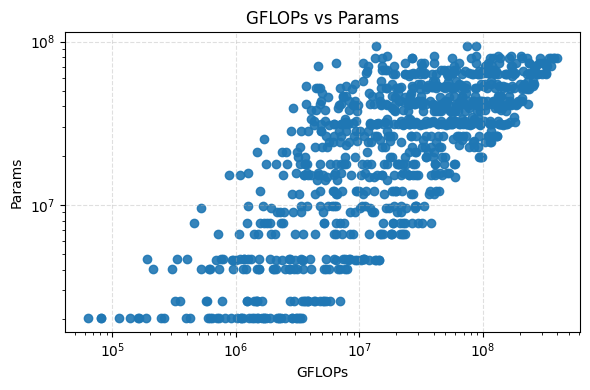

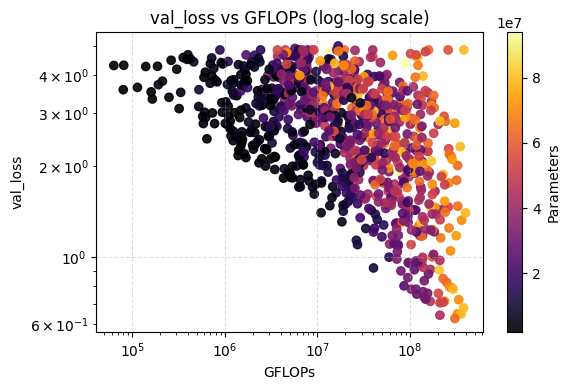

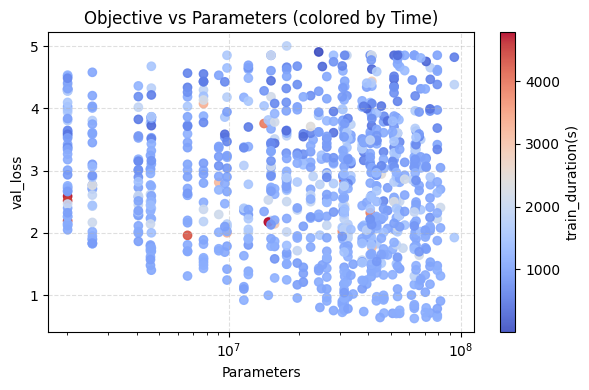

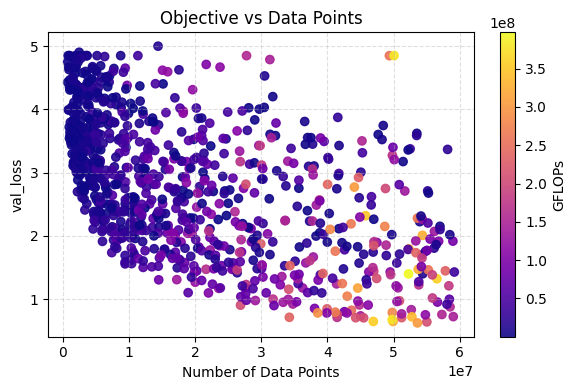

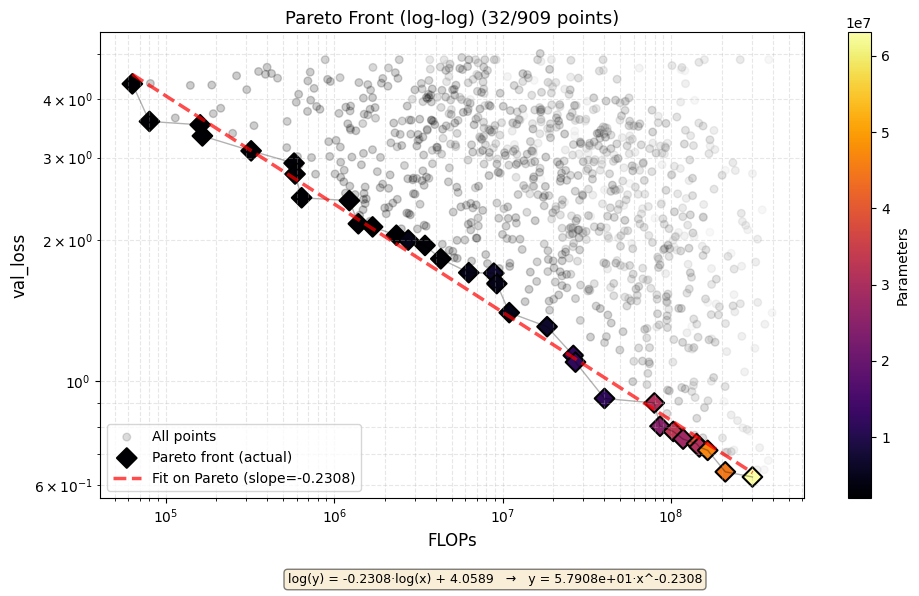

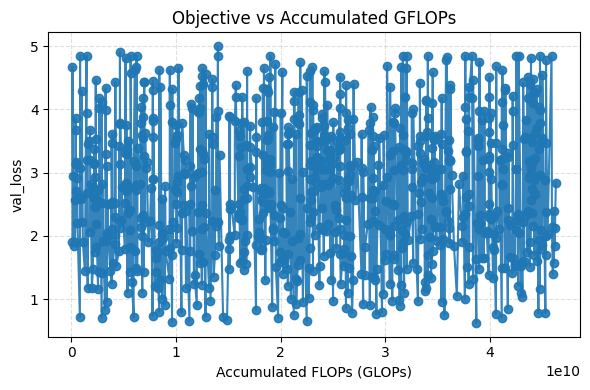

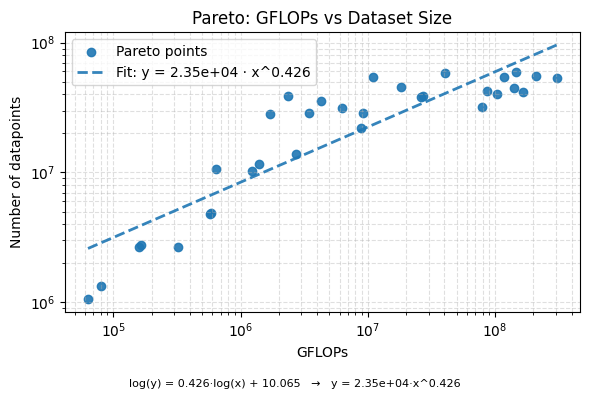

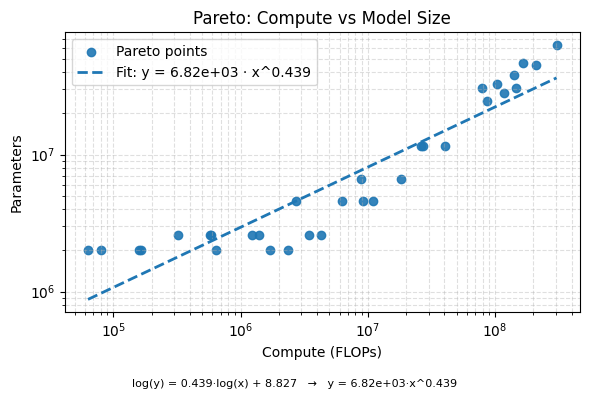

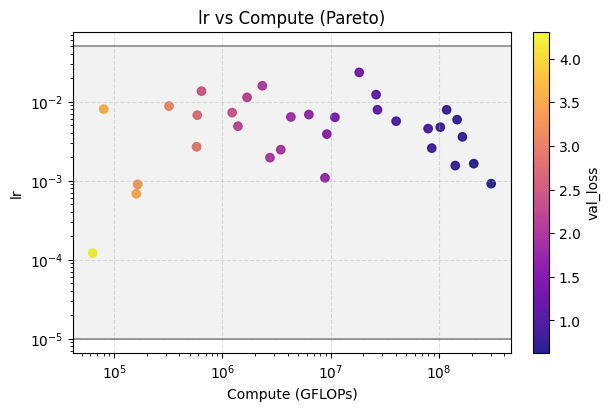

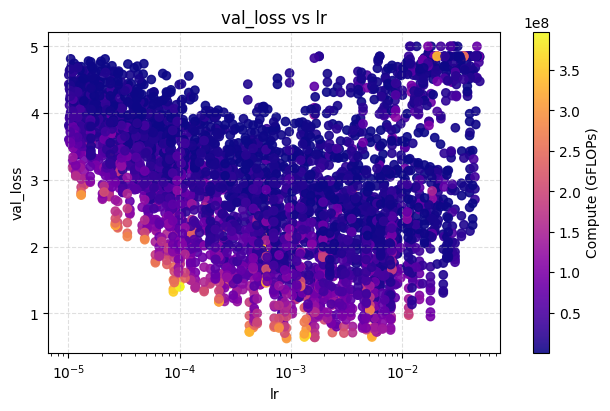

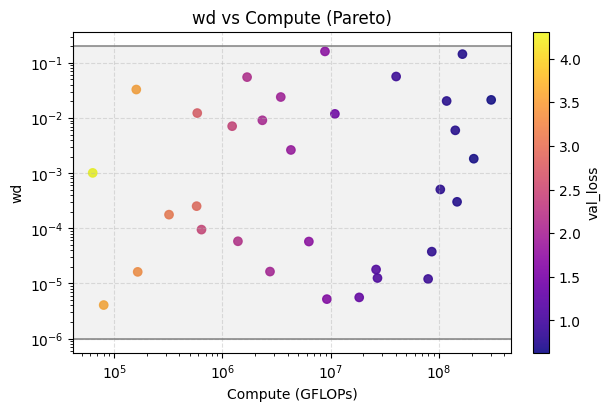

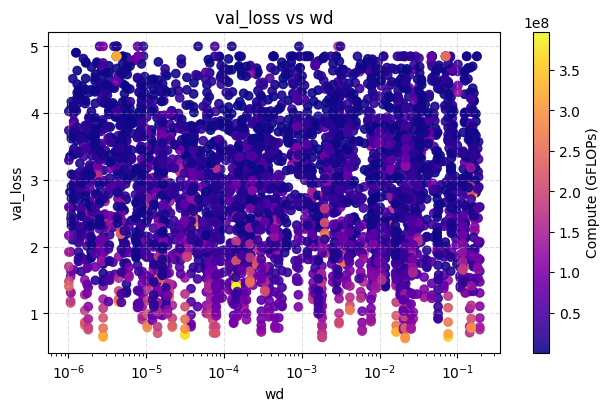

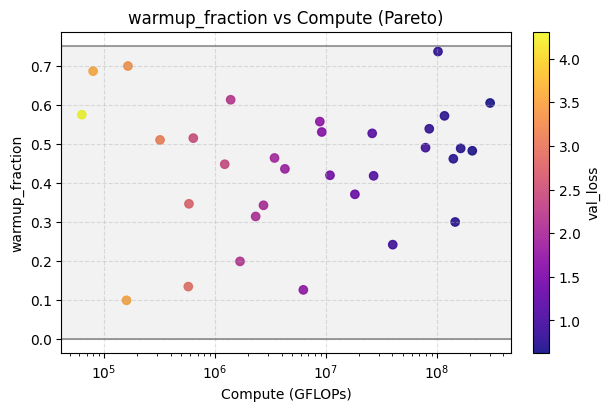

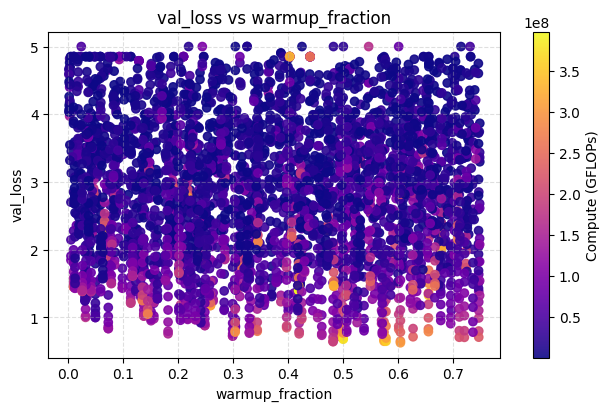

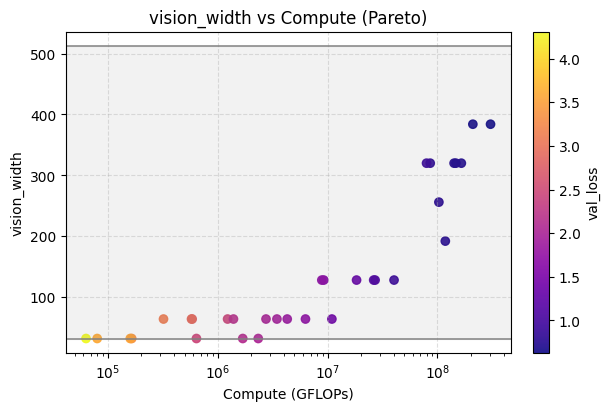

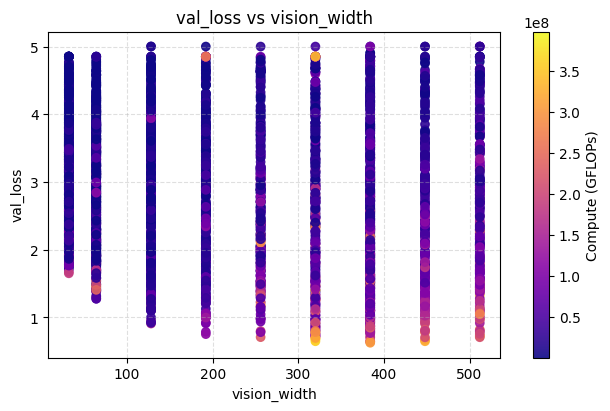

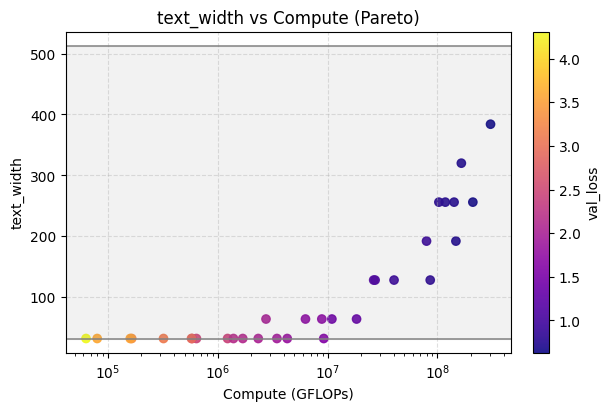

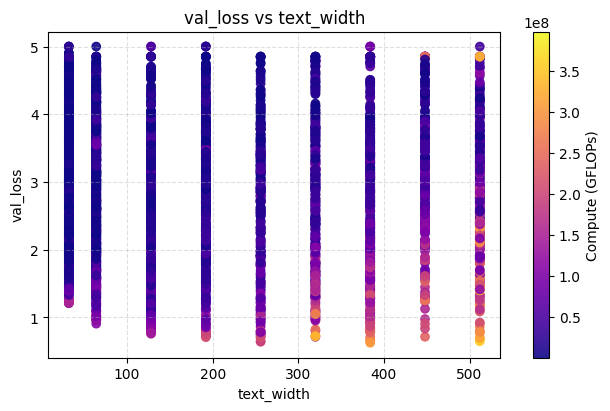

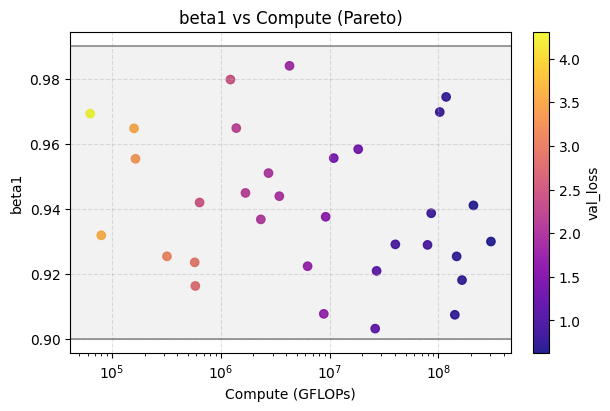

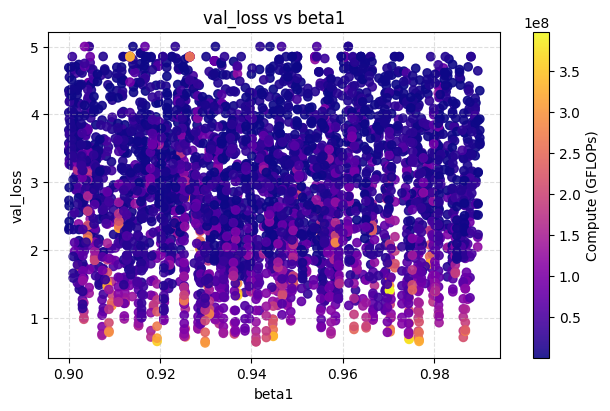

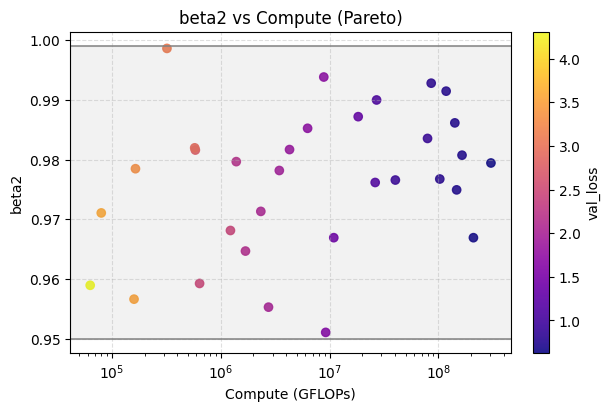

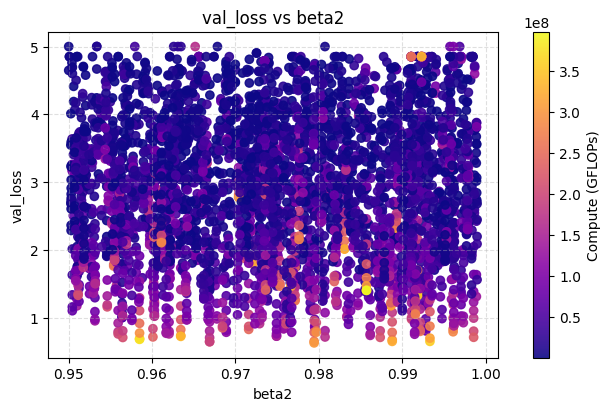

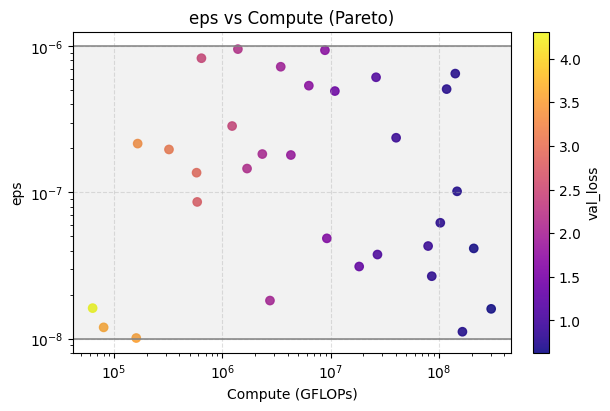

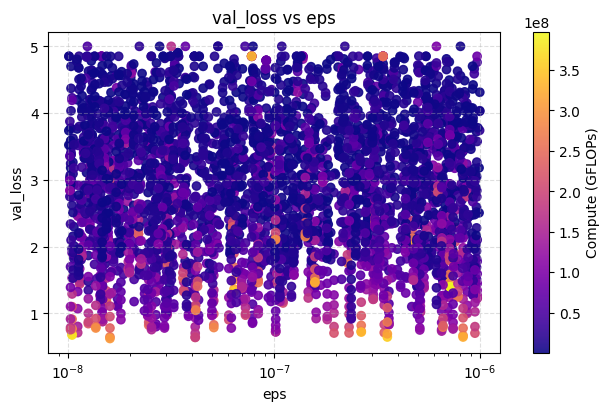

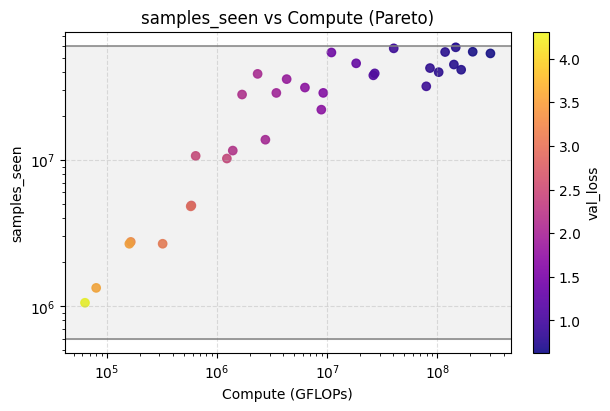

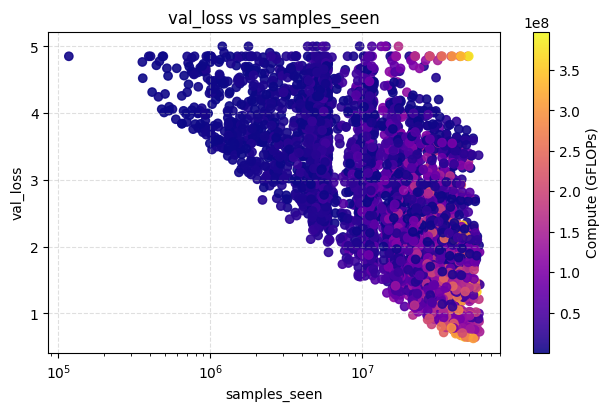

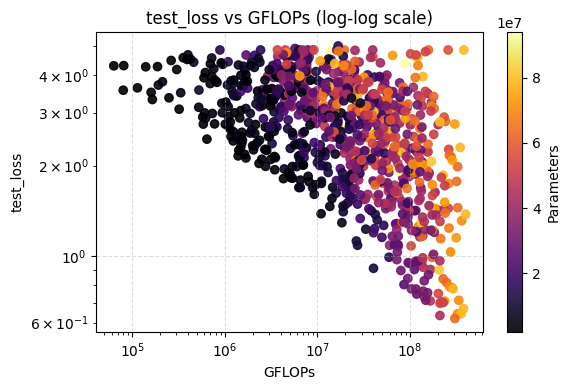

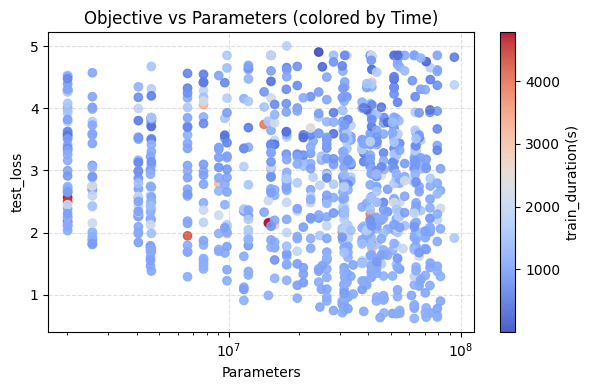

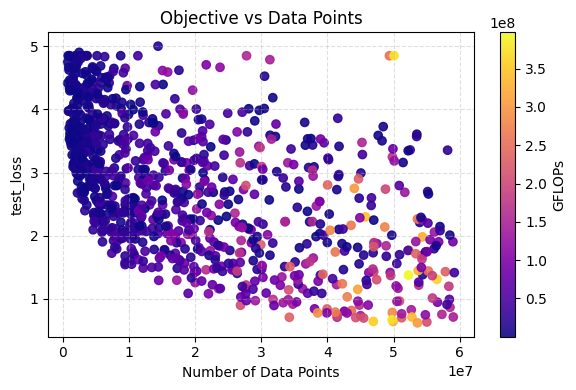

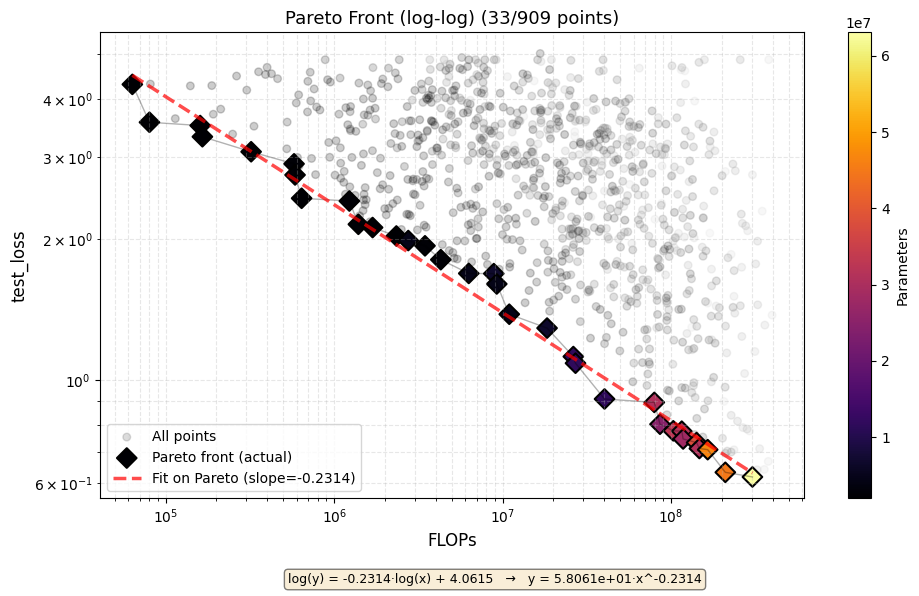

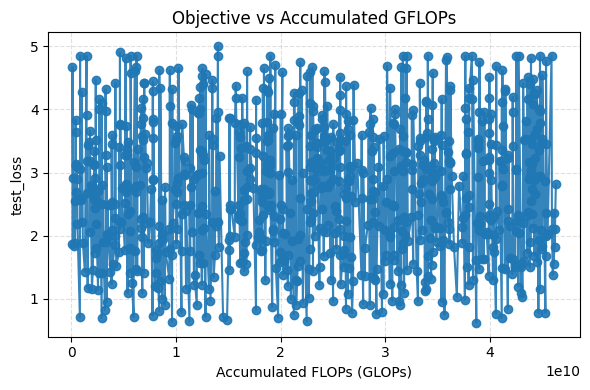

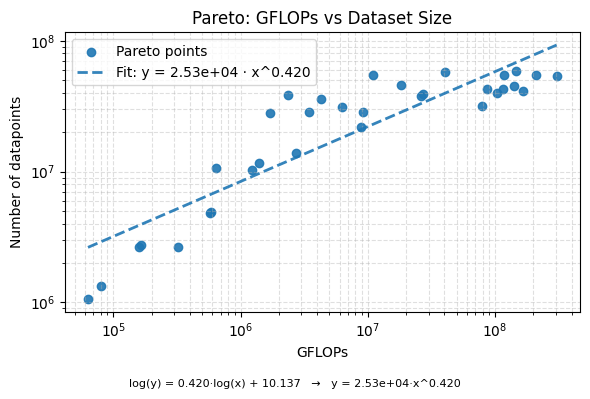

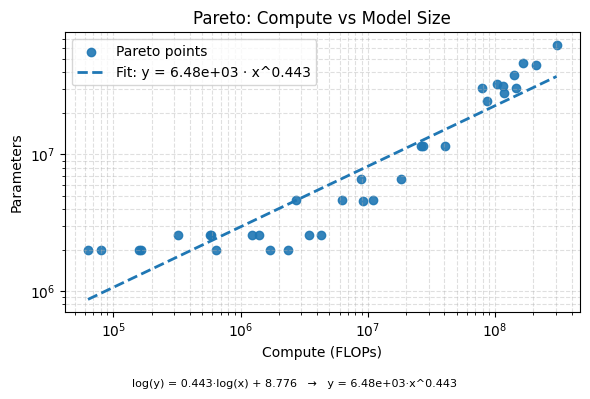

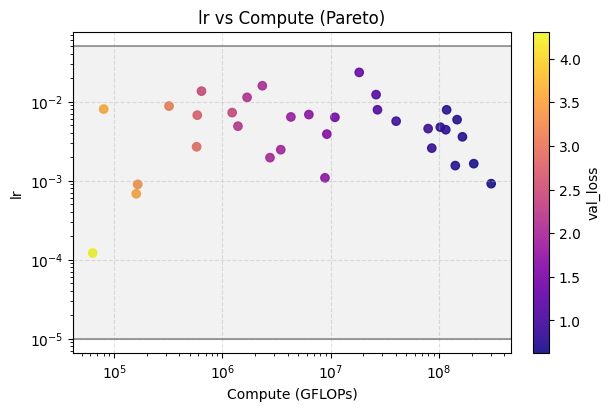

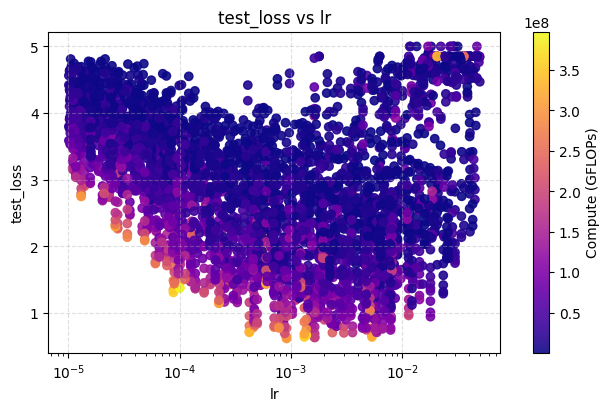

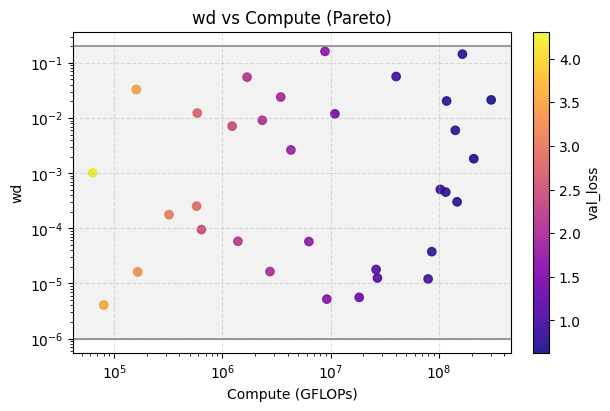

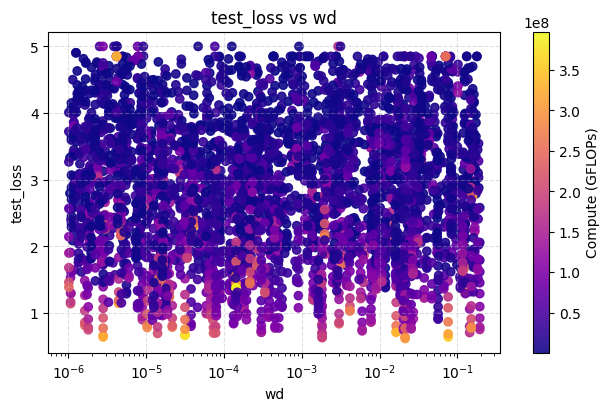

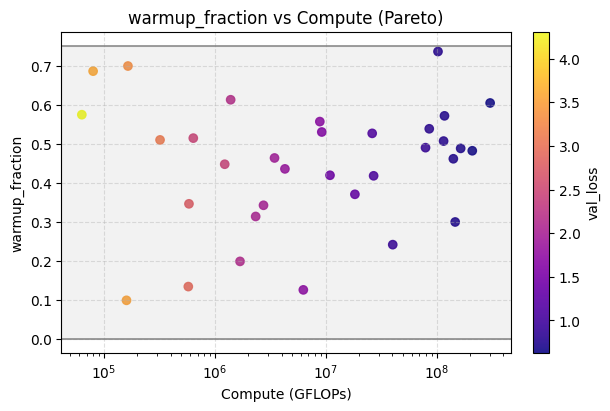

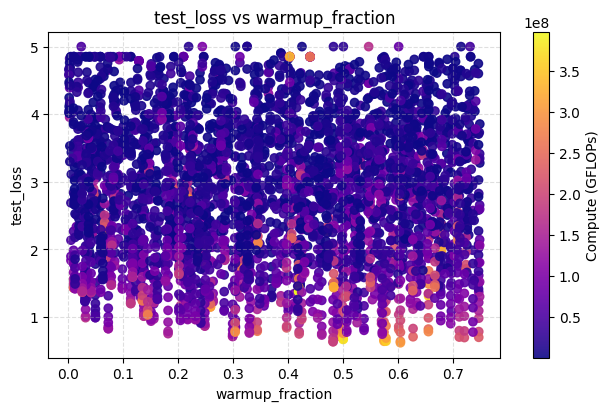

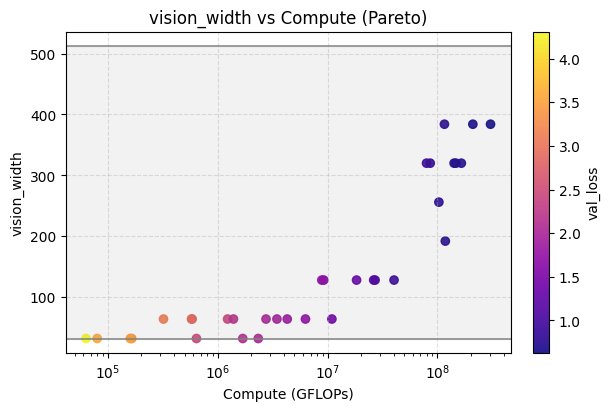

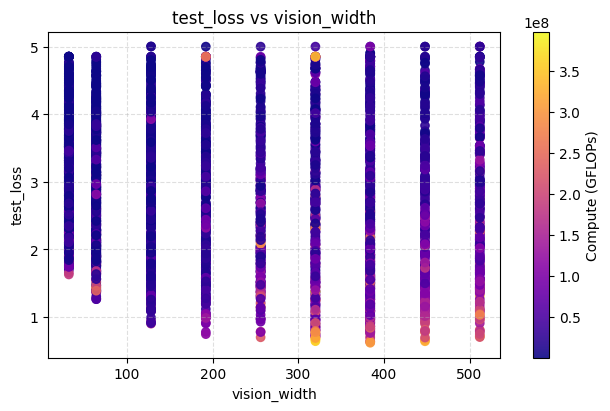

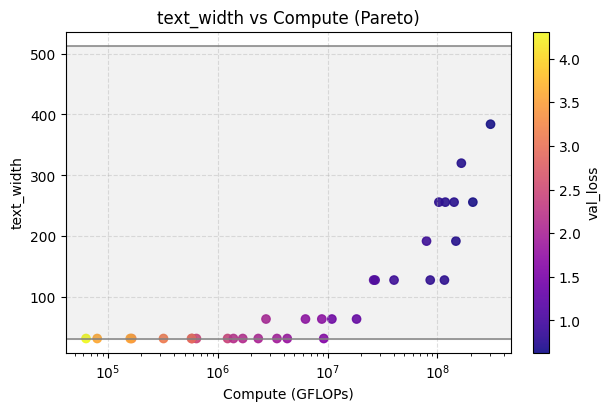

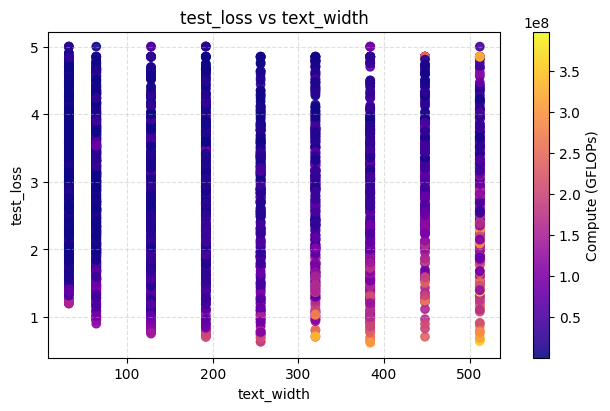

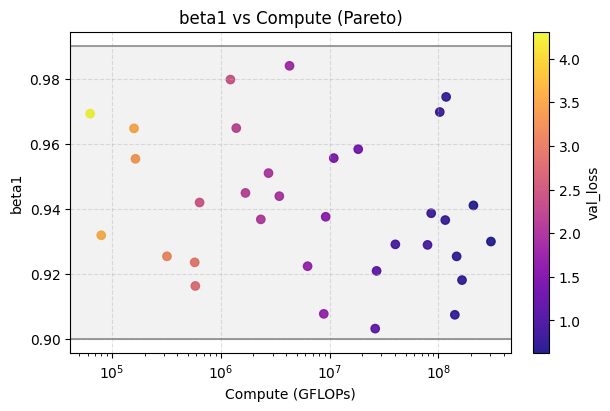

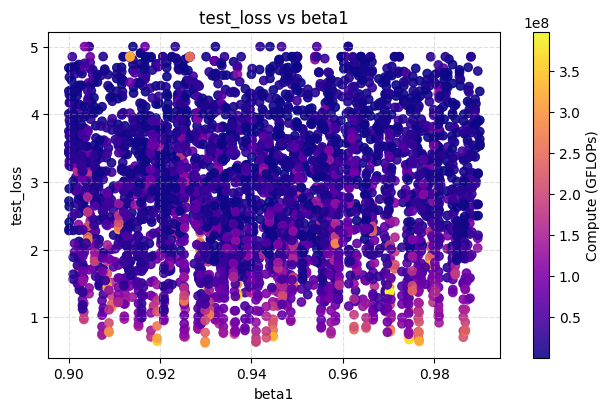

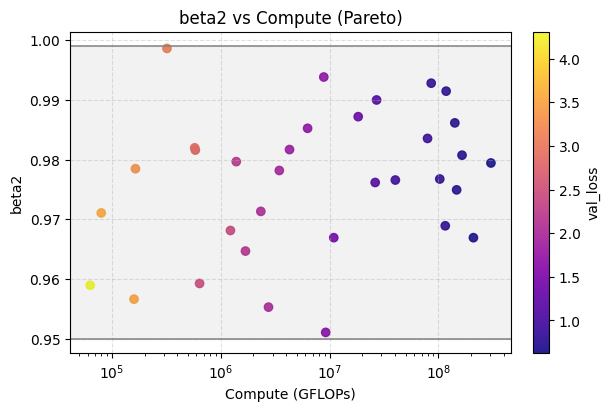

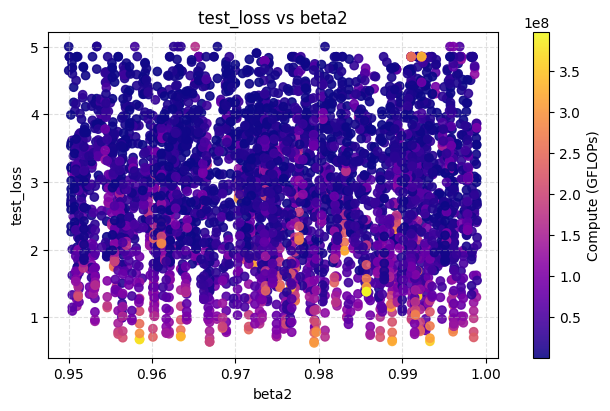

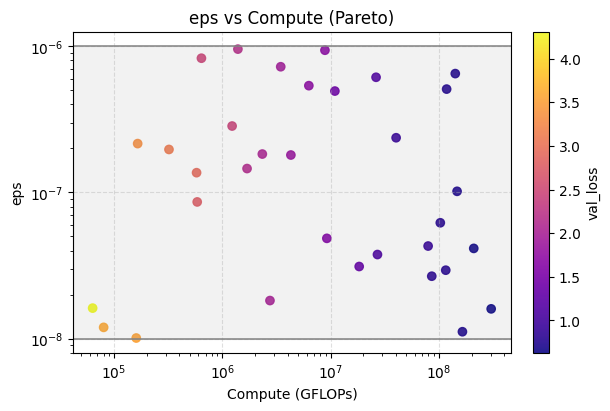

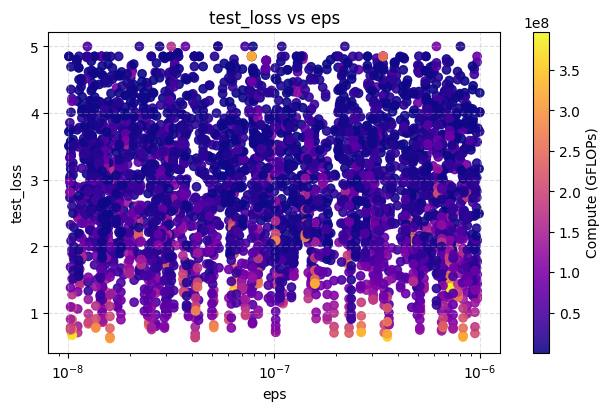

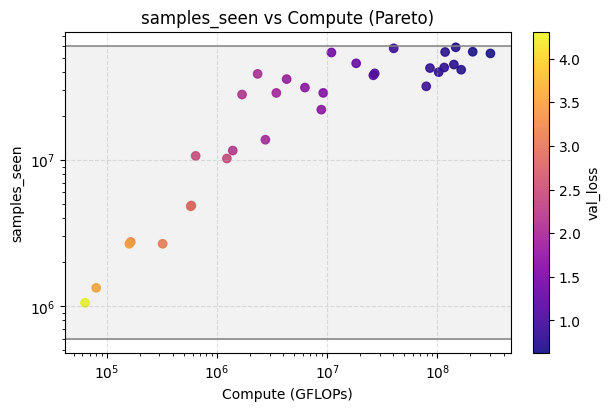

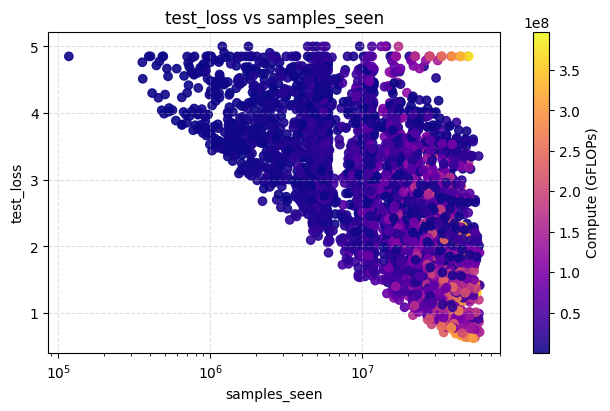

In [1]:
from train.scaling_law_plots.plotting import plot_all_objectives, plot_compute_vs_hyperparam_from_pareto

plot_all_objectives("results/optimizer=scan_space_final_biased_alpha_0_5/seed=94/configs_summary.csv")


Save 10 best and worst perfoming models

In [ ]:
import pandas as pd
import numpy as np

in_csv = "results/optimizer=scan_space_final_biased_space_alpha_0_5/configs_summary.csv"
slope = -0.2111
intercept = 3.9256
out_worst = "worst10_relative_to_scaling_law.csv"
out_best = "best10_relative_to_scaling_law.csv"

df = pd.read_csv(in_csv)
df = df[df["val_loss"].notna() & df["Total compute(GLOPs)"].notna()].copy()

log_flops = np.log(df["Total compute(GLOPs)"])
log_loss = np.log(df["val_loss"])
predicted_log_loss = slope * log_flops + intercept
df["distance_to_frontier"] = log_loss - predicted_log_loss

df["total_samples"] = df["train_num_samples"] * df["epochs"]

df_under = df[df["distance_to_frontier"] > 0].copy()
worst20 = df_under.sort_values("distance_to_frontier", ascending=False).head(20)

best20 = df.sort_values("distance_to_frontier", ascending=True).head(20)

worst20.to_csv(out_worst, index=False)
best20.to_csv(out_best, index=False)

print(f"Saved {out_worst} ({len(worst20)} rows)")
print(f"Saved {out_best} ({len(best20)} rows)")

cols = [
    "lr",
    "wd",
    "warmup_fraction",
    "beta1",
    "beta2",
    "eps",
    "text_width",
    "vision_width",
    "mparams",
    "total_samples",
    "Total compute(GLOPs)",
]

cols = [c for c in cols if c in df.columns]

mean_best = best20[cols].mean(numeric_only=True)
mean_worst = worst20[cols].mean(numeric_only=True)

comparison = pd.DataFrame({
    "best10_mean": mean_best,
    "worst10_mean": mean_worst,
    "worst_minus_best": mean_worst - mean_best,
})

comparison = comparison.reindex(comparison["worst_minus_best"].abs().sort_values(ascending=False).index)

print("\nBest 10 vs Worst 10 (largest differences first):")
print(comparison)

In [ ]:
from train.utils import sample_small_favoring_index
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

N = 10_000
n = 9
alpha = 1.0

rng = np.random.default_rng(42)

uniform_samples = rng.integers(0, n, size=N)

warped_samples = np.array([sample_small_favoring_index(n=n, alpha=alpha, rng=rng) for _ in range(N)])

uniform_counts = Counter(uniform_samples)
warped_counts = Counter(warped_samples)

x = np.arange(n)
uniform_freq = np.array([uniform_counts[i] for i in x]) / N
warped_freq = np.array([warped_counts[i] for i in x]) / N

plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, uniform_freq, width=0.4, label="uniform input")
plt.bar(x + 0.2, warped_freq, width=0.4, label=f"biased output (alpha={alpha})")
plt.xlabel("index")
plt.ylabel("probability")
plt.title("Discrete small-favoring sampling distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

df = pd.read_csv("results/scan_space_juwels_biased_scale_alpha_0_5/configs_summary.csv")
df["experiment"] = "scale space search, biased scale space, alpha 0.5"
df.to_csv("file.csv", index=False)

Calculate the optimal n_samples and model size given GFLOPs of 1e9

In [ ]:
import numpy as np

compute = 1e9

n_datapoints = 5.73e4 * np.power(compute, 0.373)
print(n_datapoints)

n_params = 3.24e3 * np.power(compute, 0.483)
print(n_params)

Pick n models from pareto frontier

In [ ]:

import pandas as pd


def pick_log_spaced_pareto_points(
        csv_path_or_df,
        *,
        compute_col: str = "Total compute(GLOPs)",
        id_col: str = "config_id",
        k: int = 8,
        drop_last_nan_id: bool = True,
) -> pd.DataFrame:
    if isinstance(csv_path_or_df, pd.DataFrame):
        df = csv_path_or_df.copy()
    else:
        df = pd.read_csv(csv_path_or_df)

    df[compute_col] = pd.to_numeric(df[compute_col], errors="coerce")
    if id_col in df.columns:
        df[id_col] = pd.to_numeric(df[id_col], errors="coerce")

    df = df.dropna(subset=[compute_col])
    df = df[df[compute_col] > 0]

    if drop_last_nan_id and id_col in df.columns:
        df = df.dropna(subset=[id_col])

    if len(df) < k:
        raise ValueError(f"Not enough rows ({len(df)}) to pick k={k} points.")

    df = df.sort_values(compute_col).reset_index(drop=True)

    df["compute_log10"] = np.log10(df[compute_col].to_numpy(dtype=float))

    lo = float(df["compute_log10"].min())
    hi = float(df["compute_log10"].max())
    targets = np.linspace(lo, hi, k)

    selected_idx = []
    remaining = set(range(len(df)))

    for t in targets:
        cand = np.array(sorted(remaining), dtype=int)
        dist = np.abs(df.loc[cand, "compute_log10"].to_numpy() - t)
        best_local = int(cand[int(np.argmin(dist))])
        selected_idx.append(best_local)
        remaining.remove(best_local)

    out = df.loc[selected_idx].copy()
    out["target_log10"] = targets
    out["log10_distance"] = np.abs(out["compute_log10"].to_numpy() - targets)

    out = out.sort_values("target_log10").reset_index(drop=True)
    return out


pick_log_spaced_pareto_points(csv_path_or_df="results/juwels_joint_results/val_loss/pareto_front.csv")

In [ ]:

import matplotlib.pyplot as plt

compute = {
    "pareto_1": 75448.31999999999,
    "pareto_2": 469073.92,
    "pareto_3": 1156055.04,
    "pareto_4": 2963865.6,
    "pareto_7": 140451840.0,
    "pareto_8": 372559052.8,
}

const = {
    "val_loss": {
        "pareto_1": 3.8565940856933594,
        "pareto_2": 3.3629720211029053,
        "pareto_3": 2.6241164207458496,
        "pareto_4": 2.3147969245910645,
        "pareto_7": 0.967,
        "pareto_8": None,
    },
    "test_loss": {
        "pareto_1": 3.8890159130096436,
        "pareto_2": 3.4083898067474365,
        "pareto_3": 2.6775715351104736,
        "pareto_4": 2.374872922897339,
        "pareto_7": 1.015,
        "pareto_8": None,
    },
    "in1k_acc1": {
        "pareto_1": 0.0064,
        "pareto_2": 0.01076,
        "pareto_3": 0.02478,
        "pareto_4": 0.03424,
        "pareto_7": 0.15148,
        "pareto_8": 0.1993,
    },
    "image_retrieval_recall@5": {
        "pareto_1": 0.011,
        "pareto_2": 0.0179,
        "pareto_3": 0.03334666043519974,
        "pareto_4": 0.04726,
        "pareto_7": 0.183,
        "pareto_8": 0.237,
    },
    "text_retrieval_recall@5": {
        "pareto_1": 0.012600000016391277,
        "pareto_2": 0.0262,
        "pareto_3": 0.05,
        "pareto_4": 0.070,
        "pareto_7": 0.275,
        "pareto_8": 0.351,
    },
}

cosine = {
    "val_loss": {
        "pareto_1": 3.938654899597168,
        "pareto_2": 3.3017454147338867,
        "pareto_3": 2.761736392974853,
        "pareto_4": 2.148553371429444,
        "pareto_7": 0.839672863483429,
        "pareto_8": 0.6029996871948242,
    },
    "test_loss": {
        "pareto_1": 3.967404365539551,
        "pareto_2": 3.3448617458343506,
        "pareto_3": 2.8208165168762207,
        "pareto_4": 2.209834337234497,
        "pareto_7": 0.8883456587791443,
        "pareto_8": 0.6409181952476501,
    },
    "in1k_acc1": {
        "pareto_1": 0.00578,
        "pareto_2": 0.01142,
        "pareto_3": 0.02,
        "pareto_4": 0.03934,
        "pareto_7": 0.1706,
        "pareto_8": 0.22894,
    },
    "image_retrieval_recall@5": {
        "pareto_1": 0.0066373450681567,
        "pareto_2": 0.0193522591143846,
        "pareto_3": 0.0300279892981052,
        "pareto_4": 0.0522590950131416,
        "pareto_7": 0.2054378241300583,
        "pareto_8": 0.2677728831768036,
    },
    "text_retrieval_recall@5": {
        "pareto_1": 0.0083999997004866,
        "pareto_2": 0.0296000000089406,
        "pareto_3": 0.0412000007927417,
        "pareto_4": 0.0839999988675117,
        "pareto_7": 0.2982000112533569,
        "pareto_8": 0.3808000087738037,
    },
}

metrics = [
    ("val_loss", "Val loss", True),
    ("test_loss", "Test loss", True),
    ("in1k_acc1", "ImageNet1k acc1", False),
    ("image_retrieval_recall@5", "MSCOCO image retrieval R@5", False),
    ("text_retrieval_recall@5", "MSCOCO text retrieval R@5", False),
]


def series_xy(metric_dict):
    xs, ys = [], []
    for k, x in compute.items():
        y = metric_dict.get(k, None)
        if y is None:
            continue
        xs.append(float(x))
        ys.append(float(y))
    xs = np.array(xs, dtype=float)
    ys = np.array(ys, dtype=float)
    order = np.argsort(xs)
    return xs[order], ys[order]


fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharex=False)

for ax, (mkey, title, is_loss) in zip(axes, metrics):
    x_c, y_c = series_xy(const[mkey])
    x_s, y_s = series_xy(cosine[mkey])

    ax.plot(x_c, y_c, marker="o", linestyle="-", label="const")
    ax.plot(x_s, y_s, marker="o", linestyle="-", label="cosine")

    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_xlabel("Compute (GFLOPs)")

    if is_loss:
        ax.set_ylabel("Loss")
        ax.invert_yaxis()
    else:
        ax.set_ylabel("Performance")

    ax.grid(True, which="both", linestyle=":", linewidth=0.7, alpha=0.7)

axes[0].legend(loc="best")
plt.tight_layout()
plt.show()


In [ ]:
from train.config import TrainConfig


def mkcfg(total_samples: int) -> TrainConfig:
    return TrainConfig(
        model="dummy",
        train_num_samples=total_samples,
        epochs=1,  # will be overwritten
        name="dummy",
        logs="dummy",
        seed=0,
        batch_size=256,
        pipeline_id=0,
        sync_neps=False,
        lr=1e-3,
        wd=1e-4,
        warmup_fraction=0.1,
    )


tests = [
    1_000_000,
    2_000_000,
    5_999_999,
    6_000_000,
    6_000_001,
    11_999_999,
    12_000_000,
    12_000_001,
    20_000_000,
    21_000_000,
    24_000_000,
    25_000_000,
    30_000_000,
    33_000_000,
    58_000_000,
    60_000_000,
]

cfgs = [mkcfg(t) for t in tests]

print(f"{'total':>12}  {'epochs':>5}  {'epoch_len':>10}  {'epochs*len':>12}")
for c in cfgs:
    total = c.train_num_samples
    epochs = c.epochs
    epoch_len = c.epoch_num_samples
    approx = epochs * epoch_len
    print(f"{total:12,d}  {epochs:5d}  {epoch_len:10,d}  {approx:12,d}")


Perplexity predictor data

Min GFLOPs: 63406.08
Max GFLOPs: 397382123.52

Counts per decade:
gflops_bin
decade_1     53
decade_2    389
decade_3    467
Name: count, dtype: int64


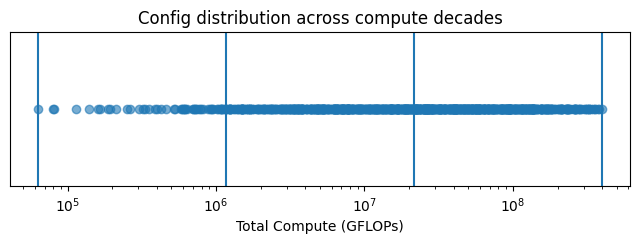


Train counts per decade:
gflops_bin
decade_1     42
decade_2    311
decade_3    373
Name: count, dtype: int64

Test counts per decade:
gflops_bin
decade_1    11
decade_2    78
decade_3    94
Name: count, dtype: int64

Total train: 726
Total test: 183

Train full epochs: (2885, 39)

Test full epochs: (778, 39)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split


def load_data(csv_path: str) -> pd.DataFrame:
    return pd.read_csv(csv_path)


def build_failure_labels(df: pd.DataFrame) -> pd.DataFrame:
    fail_df = (
        df.groupby("config_id", as_index=False)["epoch_diverged"]
        .any()
        .rename(columns={"epoch_diverged": "failed"})
    )
    fail_df["failed"] = fail_df["failed"].astype(int)
    return fail_df


def keep_only_nonfailed_last_epoch(df: pd.DataFrame) -> pd.DataFrame:
    fail_df = build_failure_labels(df)

    df = df.merge(fail_df, on="config_id", how="left")
    df_nonfailed = df[df["failed"] == 0].copy()

    df_last = (
        df_nonfailed
        .sort_values(["config_id", "epoch"])
        .drop_duplicates(subset="config_id", keep="last")
        .reset_index(drop=True)
    )
    return df_last


def create_gflops_decades(
        df: pd.DataFrame,
        gflops_col: str,
        num_decades: int = 3,
) -> tuple[pd.DataFrame, np.ndarray, list[str]]:
    min_gflops = df[gflops_col].min()
    max_gflops = df[gflops_col].max()

    print("Min GFLOPs:", min_gflops)
    print("Max GFLOPs:", max_gflops)

    log_min = np.log(min_gflops)
    log_max = np.log(max_gflops)

    bins = np.linspace(log_min, log_max, num_decades + 1)
    labels = [f"decade_{i + 1}" for i in range(num_decades)]

    df = df.copy()
    df["gflops_bin"] = pd.cut(
        np.log(df[gflops_col]),
        bins=bins,
        labels=labels,
        include_lowest=True,
    )

    return df, bins, labels


def print_decade_counts(df: pd.DataFrame, col: str = "gflops_bin") -> None:
    counts = df[col].value_counts().sort_index()
    print("\nCounts per decade:")
    print(counts)


def plot_gflops_distribution(
        df: pd.DataFrame,
        gflops_col: str,
        bins: np.ndarray,
        title: str = "Config distribution across compute decades",
) -> None:
    x = df[gflops_col]

    plt.figure(figsize=(8, 2))
    plt.scatter(x, [0] * len(x), alpha=0.6)

    for b in np.exp(bins):
        plt.axvline(b)

    plt.xscale("log")
    plt.yticks([])
    plt.xlabel("Total Compute (GFLOPs)")
    plt.title(title)
    plt.show()


def split_each_decade(
        df: pd.DataFrame,
        labels: list[str],
        test_size: float = 0.2,
        random_state: int = 42,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    train_parts = []
    test_parts = []

    for decade in labels:
        decade_df = df[df["gflops_bin"] == decade].copy()

        train_decade, test_decade = train_test_split(
            decade_df,
            test_size=test_size,
            random_state=random_state,
        )

        train_parts.append(train_decade)
        test_parts.append(test_decade)

    train_df = pd.concat(train_parts).sort_values("config_id").reset_index(drop=True)
    test_df = pd.concat(test_parts).sort_values("config_id").reset_index(drop=True)

    return train_df, test_df


def print_split_summary(train_df: pd.DataFrame, test_df: pd.DataFrame) -> None:
    print("\nTrain counts per decade:")
    print(train_df["gflops_bin"].value_counts().sort_index())

    print("\nTest counts per decade:")
    print(test_df["gflops_bin"].value_counts().sort_index())

    print("\nTotal train:", len(train_df))
    print("Total test:", len(test_df))


def enrich_with_all_epochs(
        full_df: pd.DataFrame,
        selected_configs_df: pd.DataFrame,
        keep_only_nonfailed: bool = True,
) -> pd.DataFrame:
    selected_config_ids = selected_configs_df["config_id"].unique()

    enriched_df = full_df[full_df["config_id"].isin(selected_config_ids)].copy()

    if keep_only_nonfailed:
        fail_df = build_failure_labels(full_df)
        enriched_df = enriched_df.merge(fail_df, on="config_id", how="left")
        enriched_df = enriched_df[enriched_df["failed"] == 0].copy()

    enriched_df = enriched_df.sort_values(["config_id", "epoch"]).reset_index(drop=True)
    return enriched_df


def main():
    csv_path = "../surrogate_benchmark/data.csv"
    gflops_col = "Total compute(GLOPs)"

    df = load_data(csv_path)
    df_last = keep_only_nonfailed_last_epoch(df)

    df_last, bins, labels = create_gflops_decades(
        df=df_last,
        gflops_col=gflops_col,
        num_decades=3,
    )

    print_decade_counts(df_last)

    plot_gflops_distribution(
        df=df_last,
        gflops_col=gflops_col,
        bins=bins,
    )

    train_df, test_df = split_each_decade(
        df=df_last,
        labels=labels,
        test_size=0.2,
        random_state=42,
    )

    print_split_summary(train_df, test_df)

    train_full_epochs_df = enrich_with_all_epochs(df, train_df, keep_only_nonfailed=True)
    test_full_epochs_df = enrich_with_all_epochs(df, test_df, keep_only_nonfailed=True)

    print("\nTrain full epochs:", train_full_epochs_df.shape)
    print("\nTest full epochs:", test_full_epochs_df.shape)

    train_full_epochs_df = train_full_epochs_df.sort_values(["config_id", "epoch"]).reset_index(drop=True)
    test_full_epochs_df = test_full_epochs_df.sort_values(["config_id", "epoch"]).reset_index(drop=True)

    train_full_epochs_df.to_csv("../surrogate_benchmark/performance_surrogate/splits/train.csv", index=False)
    test_full_epochs_df.to_csv("../surrogate_benchmark/performance_surrogate/splits/test.csv", index=False)


main()

Failure predictor data

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

FEATURE_COLS = [
    "config_id",
    "global_batch_size",
    "beta1",
    "beta2",
    "eps",
    "lr",
    "text_width",
    "vision_width",
    "warmup_fraction",
    "wd",
    "total_samples_planned",
]


def build_failure_labels(df: pd.DataFrame) -> pd.DataFrame:
    fail_df = (
        df.groupby("config_id", as_index=False)["epoch_diverged"]
        .any()
        .rename(columns={"epoch_diverged": "failed"})
    )
    fail_df["failed"] = fail_df["failed"].astype(int)
    return fail_df


def build_feature_table(df: pd.DataFrame, feature_cols: list[str]) -> pd.DataFrame:
    missing_cols = [col for col in feature_cols if col not in df.columns]
    if missing_cols:
        raise ValueError(f"Missing required feature columns: {missing_cols}")

    features_df = (
        df[feature_cols]
        .sort_values("config_id")
        .drop_duplicates(subset="config_id", keep="first")
        .reset_index(drop=True)
    )
    return features_df


def build_full_failure_dataset(df: pd.DataFrame, feature_cols: list[str]) -> pd.DataFrame:
    fail_df = build_failure_labels(df)
    features_df = build_feature_table(df, feature_cols)

    result = features_df.merge(fail_df, on="config_id", how="inner")
    result = result.sort_values("config_id").reset_index(drop=True)
    return result


def split_failed_configs(
        full_failure_df: pd.DataFrame,
        test_size: float = 0.2,
        random_state: int = 42,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    failed_df = full_failure_df[full_failure_df["failed"] == 1].copy()

    train_failed_df, test_failed_df = train_test_split(
        failed_df,
        test_size=test_size,
        random_state=random_state,
    )

    train_failed_df = train_failed_df.sort_values("config_id").reset_index(drop=True)
    test_failed_df = test_failed_df.sort_values("config_id").reset_index(drop=True)

    return train_failed_df, test_failed_df


def load_nonfailed_split(csv_path: str, feature_cols: list[str]) -> pd.DataFrame:
    df = pd.read_csv(csv_path)

    missing_cols = [col for col in feature_cols if col not in df.columns]
    if missing_cols:
        raise ValueError(f"Missing required columns in {csv_path}: {missing_cols}")

    result = (
        df[feature_cols]
        .sort_values("config_id")
        .drop_duplicates(subset="config_id", keep="first")
        .reset_index(drop=True)
    )
    result["failed"] = 0
    return result


def combine_failure_split(
        nonfailed_df: pd.DataFrame,
        failed_df: pd.DataFrame,
) -> pd.DataFrame:
    result = pd.concat([nonfailed_df, failed_df], ignore_index=True)
    result = result.sort_values("config_id").reset_index(drop=True)
    return result


def main() -> None:
    full_csv = "../surrogate_benchmark/data.csv"
    perplexity_train_csv = "../surrogate_benchmark/performance_surrogate/splits/train.csv"
    perplexity_test_csv = "../surrogate_benchmark/performance_surrogate/splits/test.csv"

    output_train_csv = "../surrogate_benchmark/divergence_surrogate/splits/train.csv"
    output_test_csv = "../surrogate_benchmark/divergence_surrogate/splits/test.csv"

    full_df = pd.read_csv(full_csv)

    full_failure_df = build_full_failure_dataset(full_df, FEATURE_COLS)

    train_failed_df, test_failed_df = split_failed_configs(
        full_failure_df,
        test_size=0.2,
        random_state=42,
    )

    train_nonfailed_df = load_nonfailed_split(perplexity_train_csv, FEATURE_COLS)
    test_nonfailed_df = load_nonfailed_split(perplexity_test_csv, FEATURE_COLS)

    failure_train_df = combine_failure_split(train_nonfailed_df, train_failed_df)
    failure_test_df = combine_failure_split(test_nonfailed_df, test_failed_df)

    print("Failure train shape:", failure_train_df.shape)
    print("Failure test shape:", failure_test_df.shape)

    print("\nTrain class counts:")
    print(failure_train_df["failed"].value_counts().sort_index())

    print("\nTest class counts:")
    print(failure_test_df["failed"].value_counts().sort_index())

    failure_train_df.to_csv(output_train_csv, index=False)
    failure_test_df.to_csv(output_test_csv, index=False)


if __name__ == "__main__":
    main()

Failure train shape: (798, 12)
Failure test shape: (202, 12)

Train class counts:
failed
0    726
1     72
Name: count, dtype: int64

Test class counts:
failed
0    183
1     19
Name: count, dtype: int64


In [2]:
import pandas as pd

df = pd.read_csv("../surrogate_benchmark/data.csv")

df = df.sort_values(["config_id", "epoch"])

present = set(df["config_id"])
expected = set(range(1, 1001))
missing = sorted(expected - present)

print("Missing:", missing)

df.to_csv("data_sorted.csv", index=False)

Missing: []


Build all possible model cfgs

In [4]:
from itertools import product
from train.utils import build_model_cfg
from pathlib import Path
vision_widths = [32, 64, 128, 192, 256, 320, 384, 448, 512]
text_widths = [32, 64, 128, 192, 256, 320, 384, 448, 512]

base_out = Path("model_cfg")

for text_w, vision_w in product(vision_widths, text_widths):
    head_w = 32 if vision_w == 32 else 64
    text_heads = max(1, text_w // 64)
    out_path = base_out / f"text_{text_w}_vision_{vision_w}"
    out_path.mkdir(parents=True, exist_ok=True)

    build_model_cfg(
        text_width=text_w,
        vision_width=vision_w,
        vision_head_width=head_w,
        text_heads=text_heads,
        out_path=out_path,
    )

u1 mean: 0.502499153886826
u2 mean: 0.5035372520696026
u1 std:  0.29210704177333735
u2 std:  0.2902703515107862


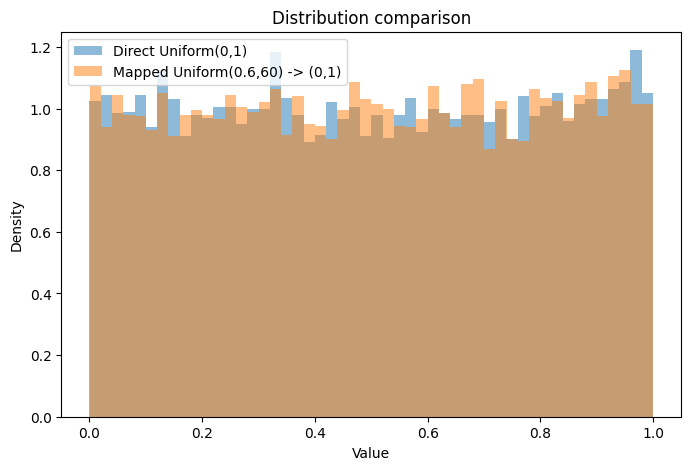

In [1]:
import numpy as np
import matplotlib.pyplot as plt

n = 10_000

u1 = np.random.uniform(0, 1, n)

x = np.random.uniform(0.6, 60, n)

# map to [0, 1]
u2 = (x - 0.6) / (60 - 0.6)

print("u1 mean:", np.mean(u1))
print("u2 mean:", np.mean(u2))
print("u1 std: ", np.std(u1))
print("u2 std: ", np.std(u2))

plt.figure(figsize=(8, 5))
plt.hist(u1, bins=50, alpha=0.5, density=True, label="Direct Uniform(0,1)")
plt.hist(u2, bins=50, alpha=0.5, density=True, label="Mapped Uniform(0.6,60) -> (0,1)")
plt.xlabel("Value")
plt.ylabel("Density")
plt.legend()
plt.title("Distribution comparison")
plt.show()